# Correct a joint covariance model with independent simulations

A covariance describes how a measurement fluctuates. Its inverse, the
precision matrix, determines which combinations of data receive weight in a
fit. Inverting a noisy sample covariance amplifies sampling noise, and a
sample covariance from $N$ mean-subtracted realizations has rank at most
$N-1$, so a joint two-point/three-point vector can have more rows than
available independent simulations.

The precision-matrix expansion (PME) of
[Friedrich and Eifler, arXiv:1703.07786](https://arxiv.org/abs/1703.07786)
expands around an independently specified analytic covariance, and the method
inverts only that analytic matrix. This notebook explains the expansion, the
correction to products of noisy covariance estimates, and the particular
advantage when a known covariance component can stay out of the simulations.

The calculations in Sections 1–5 use controlled Gaussian vectors with prescribed truth.
They are not DES mocks: they have correlated two-point-like and three-point-like rows
with different units. Knowing the truth separates truncation error,
finite-simulation noise, and the calibration of quoted parameter errors. Sections 6–9 connect this exercise to Rafael's downloaded maps. The
[undergraduate notes](notes/covariance_from_simulations/covariance_from_simulations.pdf)
explain the statistical steps and their physical meaning.

**Model and data.** The controlled experiment fixes every input:

| Choice | Value |
| --- | --- |
| Rows | 24: twelve two-point-like at scale $10^{-4}$, twelve three-point-like at scale $10^{-8}$ |
| Training vectors | $N=18$, fewer than the 24 rows, so the full sample covariance has no inverse |
| Validation vectors | 1200, drawn from a separate random-number stream |
| Seed | 1937; the wrapper prints the training and validation streams |
| Estimators | Shared [precision module](../../external_modules/code/cosmolike_core/cosmolike_notebook_utils/covariance/precision.py), also used by the forecast driver |
| Physics | none: no compiled CosmoLike model and no CAMB run |
| Threads | one BLAS worker, including in a reused notebook kernel |

Words used throughout:

- The **precision matrix** is the inverse covariance; a Gaussian likelihood
  weights data residuals with it.
- **Whitening** multiplies a vector by $L^{-1}$, where $M=LL^\mathsf{T}$ is the
  Cholesky factorization of the model covariance, so every entry loses its
  units and model correlations.
- The **Wishart distribution** is the exact sampling distribution of a sample
  covariance built from independent Gaussian vectors.
- The **spectral radius** $\rho(X)$ is the largest absolute eigenvalue of $X$;
  the expansion below converges only when $\rho(X)<1$.
- **`finite_sas`** names the finite side-angle-side three-point estimator,
  which bins triangles by two side lengths and the angle between them.
- The **Hartlap factor** ([Hartlap, Simon and Schneider,
  arXiv:astro-ph/0608064](https://arxiv.org/abs/astro-ph/0608064)) rescales an
  inverted sample covariance by $(N_s-N_d-2)/(N_s-1)$; the PME is a different
  construction and uses no such rescaling.

## 1. Set up a reproducible, bounded experiment

The wrapper constructs matrices and draws small Gaussian vectors. It imports
no native CosmoLike model and runs no CAMB calculation. The statistical estimators come from the shared
[precision module](../../external_modules/code/cosmolike_core/cosmolike_notebook_utils/covariance/precision.py),
which the forecast driver also uses. Training and validation have separate random-number streams, the
wrapper fixes the analytic model before drawing either stream, and the
experiment never replaces a draw because its estimate is inconvenient. BLAS
uses one worker, including in a reused notebook kernel.

In [1]:
# Setup only: this cell loads the plotting and statistical routines.
# No DES map, cosmological model or covariance calculation is started here.
# Run this notebook from the des_3pcf directory so the paths below refer to
# this checkout rather than another project's compiled interface.
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
from pathlib import Path
import sys
import importlib

# Set workers before importing NumPy. This small example needs one worker;
# BLAS must remain single-threaded in the Cocoa workflow.
for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
PROJECT = Path.cwd()
if not (PROJECT / "README.md").is_file():
    raise ValueError("Use des_3pcf as this notebook's working directory.")
CORE = PROJECT.parents[1] / "external_modules" / "code" / "cosmolike_core"
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(PROJECT / "scripts"))
sys.path.insert(0, str(CORE))
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from threadpoolctl import threadpool_info, threadpool_limits
import cosmolike_des_3pcf_precision_wrappers as nw

# A notebook kernel may already have imported a BLAS library. Limit those
# loaded libraries too; environment variables alone would not change them.
blas_limit = threadpool_limits(limits=1, user_api="blas")
for library in threadpool_info():
    if library["user_api"] == "blas" and library["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS library has more than one worker.")
# The shared plotting package accepts ordinary arrays and does not run
# this project's native interface. Its name begins with a digit, so importlib
# loads it by its full module name.
plots = importlib.import_module(name="cosmolike_notebook_utils.3pcf")

In [2]:
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

## 2. Define what is known and what simulations must estimate

Let the true covariance be $C=A+B$, where $A$ and $B$ are covariances of
independent random contributions to the same full data vector. The model is
$M=A+B_m$: $A$ is known, and $B_m$ imperfectly approximates $B$. The
controlled construction draws independent Gaussian vectors $a$ and $b$ and
forms the measured vector $d=a+b$, so simulating $b$ alone estimates $B$
without the sampling noise of $a$.

This is not a two-point/three-point block split. A matrix containing only a
cross block has zero diagonal variances but nonzero off-diagonal entries; it
is generally indefinite and is not a covariance of random contributions. Nor
does subtracting $A$ from a sample covariance of $d$ make the result a Wishart
sample of $B$. Physical shear summaries are nonlinear functions of signal and
shape noise, so the three-point covariance contains mixed signal/noise powers
as well as noise-only terms, and a diagonal white-noise $A$ does not describe
all noise terms of the Map3 covariance. A survey decomposition of this kind
needs noiseless catalogues, paired realizations or a noise switch that
establish a positive semidefinite $B$ and a known $A$ consistently, including
the two/three-point cross-covariance, the same masks and the same estimator;
the controlled additive-Gaussian construction does not prove one.

The first 12 controlled rows are two-point-like, the last 12
three-point-like, with row scales $10^{-4}$ and $10^{-8}$ chosen to expose
mixed units, not to calibrate a survey. The matrix below keeps the
cross-correlations. The experiment uses $N=18$ training vectors for $p=24$
rows, so the centered full sample cannot have an inverse, and nothing below
attempts one.

Controlled Gaussian joint vectors; not DES simulations.
Training vectors: 18
Rows: 24
Full sample rank: 17
Attempted sample inverse: False
Separate streams: (0,) (1,)


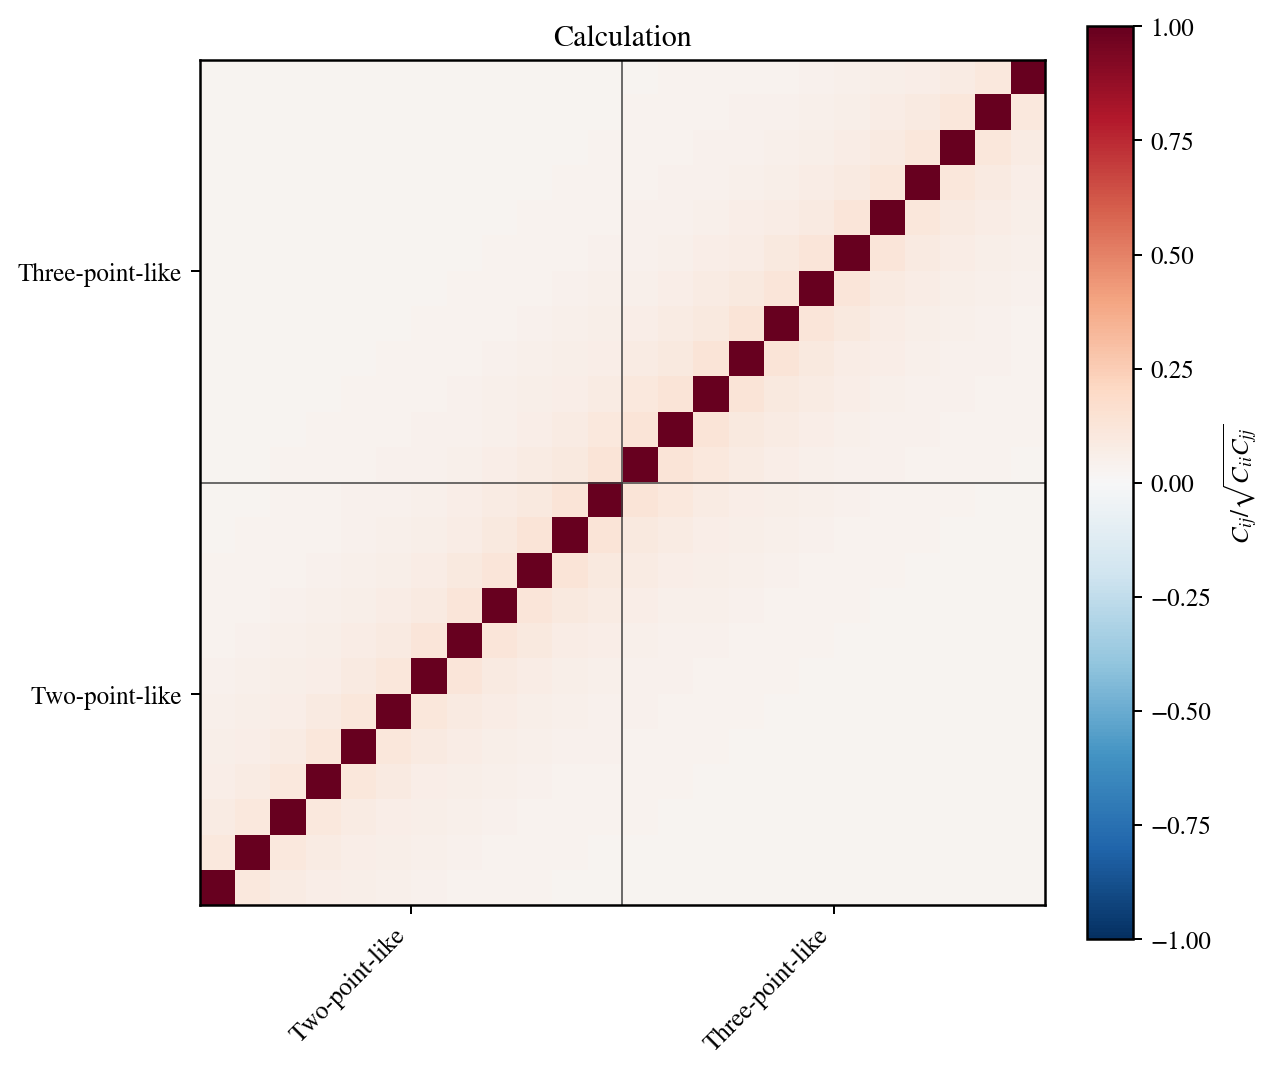

In [3]:
# Use an artificial joint vector whose true covariance is known exactly.
# The first 12 rows mimic two-point measurements and the last 12 mimic
# three-point measurements. Their scales differ, and their cross block is
# nonzero, so the exercise tests the full joint weighting.
# Eighteen training vectors cannot give an invertible 24-row sample
# covariance: after fitting the mean its rank is at most 17.
# PME can still run because it inverts the analytic model, not that sample.
report = nw.controlled_precision_study(
    # Total number of entries in each measured vector.
    ndata=24,
    # Independent draws used to estimate the covariance correction.
    training_count=18,
    # Separate cheap Gaussian draws; these are not additional DES skies.
    validation_count=1200,
    # Fix the teaching experiment so its printed results are reproducible.
    seed=1937,
)
print(report["system"]["scope"])
print("Training vectors:", report["training_count"])
print("Rows:", report["system"]["truth"].shape[0])
print("Full sample rank:", report["sample_rank_in_model_units"])
print("Attempted sample inverse:", report["sample_inverse_attempted"])
print("Separate streams:", report["training_stream"],
      report["validation_stream"])
# Divide covariance entries by their two standard deviations for this plot.
# This displays correlations without hiding the small-unit third-order block.
plots.plot_correlation(
    covariance=report["system"]["truth"],
    block_sizes=[12, 12],
    block_labels=["Two-point-like", "Three-point-like"],
)

## 3. Expand in dimensionless model errors

Factor the analytic covariance as $M=LL^\mathsf{T}$. Multiplying data by
$L^{-1}$ removes its model units and correlations; this is called whitening.
In these coordinates define

$$X=L^{-1}(C-M)L^{-\mathsf T}.$$

Then

$$C^{-1}=L^{-\mathsf T}(I+X)^{-1}L^{-1}
=L^{-\mathsf T}(I-X+X^2-\cdots)L^{-1}.$$

The expansion converges if the spectral radius $\rho(X)$, the largest absolute
eigenvalue, stays below one, and the second-order expression leaves a
remainder bounded in these dimensionless model coordinates by
$\rho^3/(1-\rho)$. That bound does not constrain individual dimensional matrix
entries or every marginalized parameter error.

Because the controlled example knows $C$, the notebook calculates the true
$\rho(X)$ and the exact second-order truncation error. With real simulations,
a radius computed from a noisy sample only diagnoses that sample; it does not
prove that the unknown true expansion converges. The deterministic polynomial
$I-X+X^2$ is positive for symmetric $X$; a bias-corrected noisy estimator of
that polynomial need not be.

In [4]:
# In this teaching experiment only, we know the true covariance. We can
# therefore distinguish an error in the analytic model from the random
# error caused by estimating that covariance with 18 training vectors.
# The spectral radius is the largest absolute eigenvalue of the whitened
# model error. If the TRUE radius is below one, its inverse series converges.
# The noisy estimated radius is a different quantity; a singular sample
# already has residual eigenvalues of -1 even when the true model is good.
print("True residual spectral radius:",
      report["true_residual_spectral_radius"])
print("Model-unit remainder bound:",
      report["true_second_order_operator_error_bound"])
print("Exact second-order relative precision error:",
      report["diagnostics"]["exact_second_order"]
      ["relative_precision_frobenius_error"])
print("Estimated radii and positivity diagnostics:",
      report["estimator_diagnostics"])

True residual spectral radius: 0.13411494708014332
Model-unit remainder bound: 0.0027859370874408276
Exact second-order relative precision error: 0.0005025586134356025
Estimated radii and positivity diagnostics: {'component': {'estimated_residual_spectral_radius': 0.4024162430184342, 'minimum_polynomial_eigenvalue': 0.653755481036972, 'independent_count': 18, 'order': 2, 'sample_scope': 'separately_simulated_B_covariance'}, 'full': {'estimated_residual_spectral_radius': 2.9396507416907482, 'minimum_polynomial_eigenvalue': -1.9247899444826453, 'independent_count': 18, 'order': 2}}


## 4. Correct the product of noisy covariances

For independent Gaussian summary vectors, an unbiased sample covariance
$\widehat B$ has a Wishart distribution with $\nu=N-1$ degrees of freedom. Set
$S=L^{-1}\widehat B L^{-\mathsf T}$ and $T=L^{-1}B_m L^{-\mathsf T}$. Although
$S$ is unbiased, $S^2$ is not an unbiased estimate of $(\mathbb E S)^2$; the
correction is

$$Q=\frac{\nu^2S^2-\nu S\,\mathrm{tr}(S)}{\nu^2+\nu-2}.$$

The second-order precision polynomial of Friedrich and Eifler
(arXiv:1703.07786) then takes the symmetric form

$$\widehat\Psi_2=L^{-\mathsf T}
[I-S+T+Q-ST-TS+T^2]L^{-1}.$$

Both $ST$ and $TS$ appear because covariance matrices generally do not
commute. The estimator makes the truncated precision unbiased in expectation;
it does not make the full inverse unbiased, and it never inverts $\widehat B$.

The full-covariance route is the special case $A=0$, $B_m=M$, with polynomial
$3I-3S_C+Q_C$, where $S_C$ whitens a sample of the whole covariance.
Inserting $A+\widehat B$ into that full-Wishart correction is wrong, because
adding a fixed matrix changes the distribution; the component estimator
corrects the noisy $B$ part and leaves the known $A$ part fixed.

An alternative uses independent groups. If $S_1$ and $S_2$ independently
estimate the same whitened full covariance, then
$\mathbb E[(S_1S_2+S_2S_1)/2]=(\mathbb E S)^2$; the identity needs unbiased
independent groups, not Gaussian summaries. Here each group contributes
$A+\widehat B_i$ from one half of the same training budget, so each half has
noisier covariance entries. Independence removes the product bias, not the
truncation error or the finite-sample uncertainty.

truth positive_precision relative precision error = 2.7076603902301054e-16
analytic positive_precision relative precision error = 0.03604560126458969
exact_second_order positive_precision relative precision error = 0.0005025586134356025
component_wishart positive_precision relative precision error = 0.19056457595048829
full_wishart refused_nonpositive_precision relative precision error = 1.922485575393032
component_split positive_precision relative precision error = 0.20388279594938835


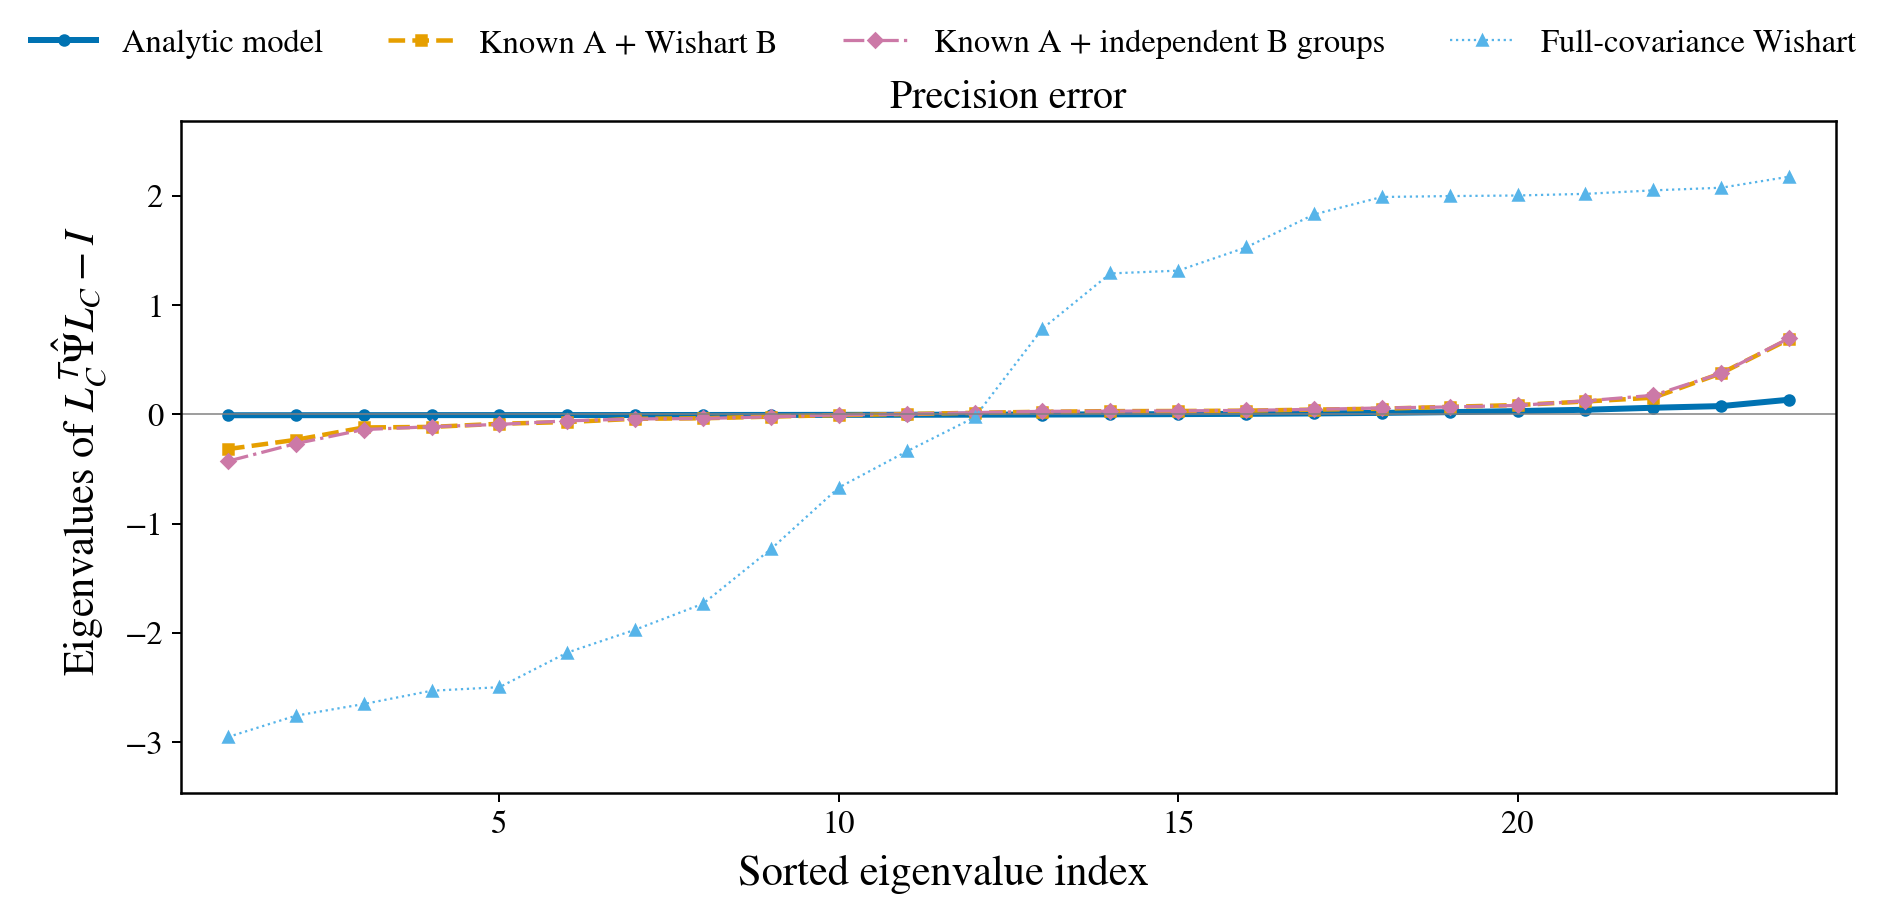

In [5]:
# Compare the analytic model, exact truncated expansion and simulation
# estimates. The exact truncated result isolates the error from omitting
# higher powers; the estimated results also contain finite-sample noise.
# A reported nonpositive precision cannot weight a Gaussian likelihood.
# The plot keeps such failures visible instead of repairing eigenvalues.
for method, diagnostics in report["diagnostics"].items():
    print(method, diagnostics["inference_status"],
          "relative precision error =",
          diagnostics["relative_precision_frobenius_error"])
precision_figure, precision_axes = nw.plot_precision_errors(report=report)
plt.show()

Each line above sorts the eigenvalues of $L_C^{\mathsf T}\widehat\Psi L_C-I$,
where $C=L_CL_C^{\mathsf T}$ factorizes the known true covariance. Zero means
exact precision in that direction, and sorting does not identify a shared
physical eigenvector across methods. An eigenvalue at or below $-1$ marks a
nonpositive precision direction and prohibits using that estimate as a
Gaussian likelihood; the code keeps such a failure in the diagnostic plot,
refuses its parameter errors, and never clips eigenvalues.

One realization need not rank the estimators by their average performance. The
known-component method reduces the source of sampling noise in this
experiment, and its benefit depends on the covariance decomposition and the
quality of the analytic model; the source tests separately compare a small
Gaussian ensemble with the expected truncated series.

In this realization, the analytic model is closer to the true precision than
either noisy correction. Estimating only $B$ reduces the error substantially
relative to estimating the whole covariance, but eighteen training
realizations do not make a correction beneficial relative to this good
analytic starting model; more simulations and independent validation must
decide whether to apply one. The random draw stays as drawn.

## 5. Check parameter errors on independent validation data

The controlled mean is linear, $\mu=D\boldsymbol p$, with three prescribed
response columns named amplitude, alignment and shape; the names describe this
exercise, not physical DES derivatives. For a positive precision estimate,
define

$$F=D^{\mathsf T}\widehat\Psi D,\qquad
H=F^{-1}D^{\mathsf T}\widehat\Psi,\qquad
\widehat{\boldsymbol p}=Hd.$$

The Gaussian fit quotes covariance $F^{-1}$, while its actual
repeated-experiment covariance is $HCH^{\mathsf T}$. The two agree for the
true precision and can differ when a noisy precision misweights the data.

The figure compares quoted errors with the known-truth errors, and the output
below it compares held-out fitted-parameter variances with the quoted
variances and with the exact $HCH^{\mathsf T}$ prediction. No validation draw
entered a covariance estimate or tuned $M$. The test covers one fitted
precision realization; a production coverage study must repeat both training
and validation constructions and account for any non-Gaussian likelihood.

No parameter contour for Full-covariance Wishart: nonpositive precision.


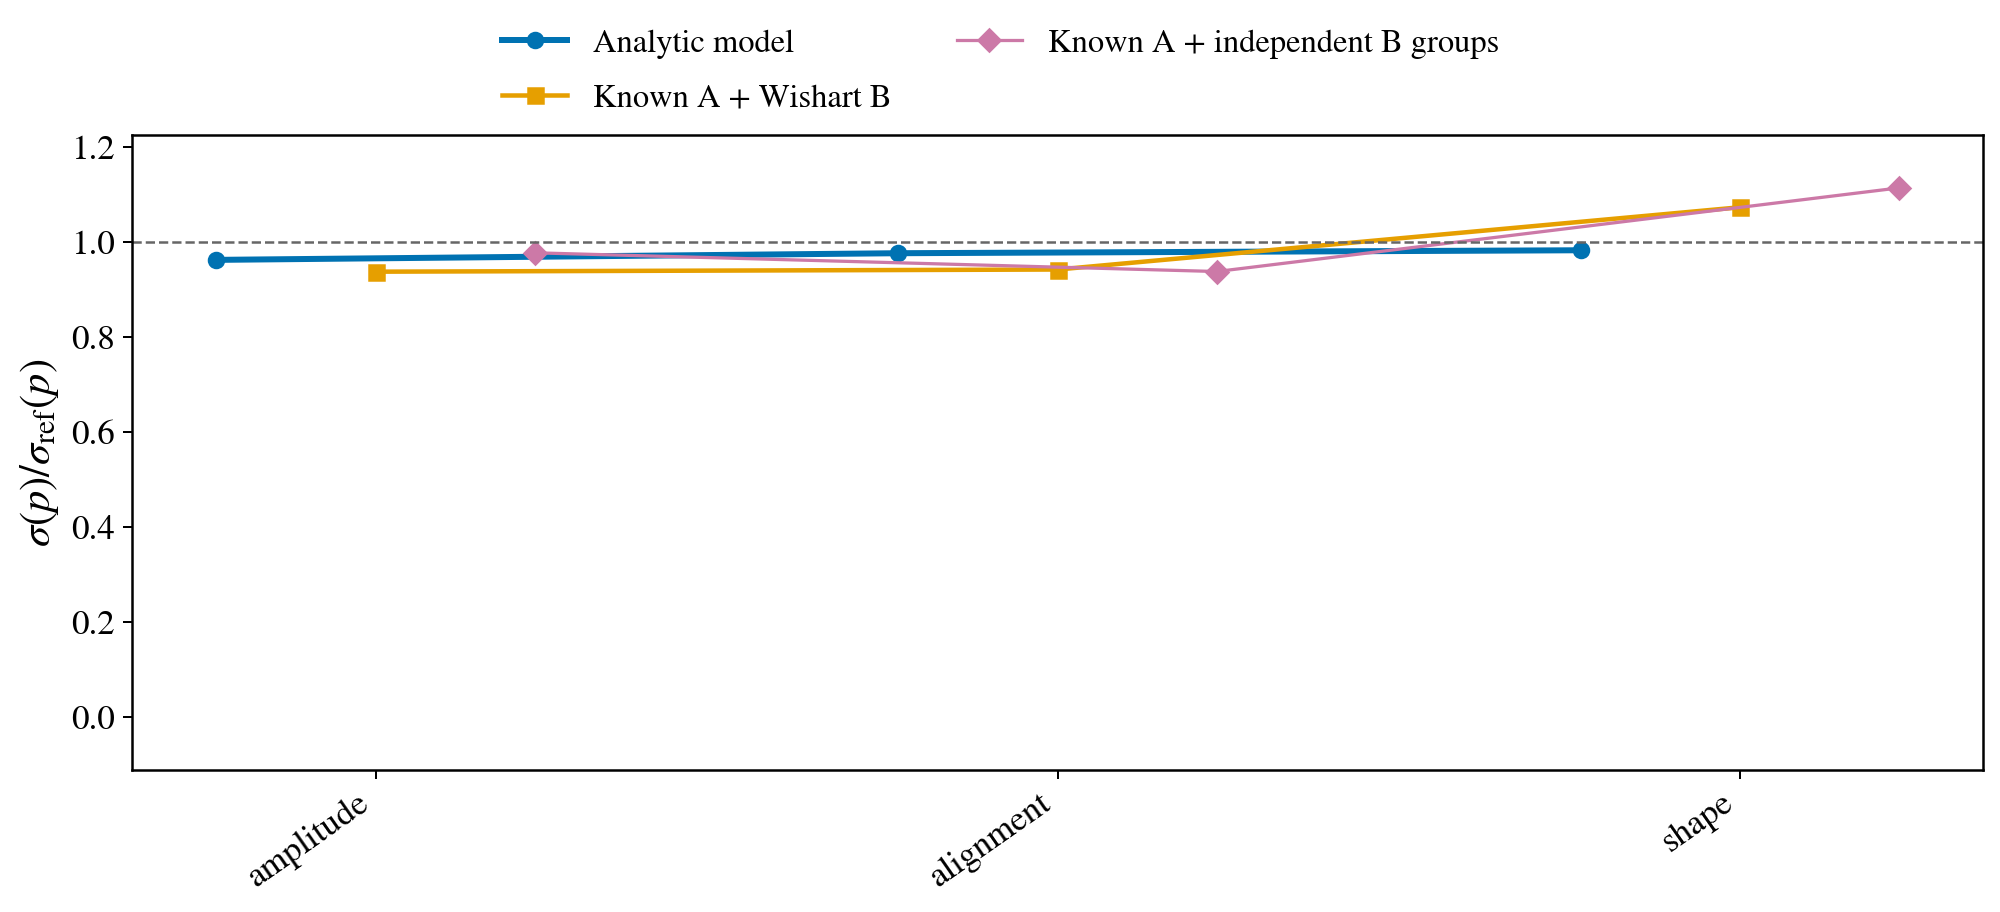

truth
Exact variance / quoted variance: [1. 1. 1.]
Validation variance / quoted variance: [0.9353738  0.9920423  1.01861395]
Validation mean quadratic / row count: 0.9846148847820811
analytic
Exact variance / quoted variance: [1.08189129 1.0510291  1.03793727]
Validation variance / quoted variance: [1.01362679 1.04248163 1.05817678]
Validation mean quadratic / row count: 0.9976727956573369
exact_second_order
Exact variance / quoted variance: [1.00121846 1.00021978 1.00011629]
Validation variance / quoted variance: [0.93652051 0.99225723 1.01873673]
Validation mean quadratic / row count: 0.984744958853503
component_wishart
Exact variance / quoted variance: [1.16523076 1.15038435 0.90063282]
Validation variance / quoted variance: [1.06835777 1.14474793 0.90662449]
Validation mean quadratic / row count: 1.0093599257713866
full_wishart is excluded from parameter inference.
component_split
Exact variance / quoted variance: [1.09929729 1.16097989 0.85663332]
Validation variance / quoted vari

In [6]:
# A good covariance is useful only if it gives reliable parameter errors.
# The teaching model has prescribed derivative columns, so we can compare
# the scatter expected under the known true covariance with the error bars
# that each approximate precision would quote.
# The independent validation vectors provide a second, empirical check.
parameter_figure, parameter_axis = nw.plot_precision_parameter_errors(
    report=report,
)
plt.show()
# A variance ratio of one means the quoted variance matches the scatter.
# Greater than one means the quoted error bar is too small. The validation
# ratio fluctuates because it is estimated from a finite independent sample.
for method, diagnostics in report["diagnostics"].items():
    if diagnostics["positive"]:
        print(method)
        print("Exact variance / quoted variance:",
              diagnostics["exact_variance_over_quoted"])
        print("Validation variance / quoted variance:",
              diagnostics["validation_variance_over_quoted"])
# This last diagnostic checks the whole data-vector weighting, rather
        # than only the selected parameter directions. The model mean is
        # known here; fitting a mean would change the reference expectation.
        print("Validation mean quadratic / row count:",
              diagnostics["validation_mean_quadratic_per_row"])
    else:
        print(method, "is excluded from parameter inference.")

## 6. Replace the controlled vectors with real joint realizations

A real archive must contain `vectors[N,p]`, ordered `row_labels[p]`,
`row_kind[p]`, `parent_ids[N]`, and the scalar string `estimator`. The loader
checks the row labels, row kinds and the estimator string, and it never
reorders columns. Those checks are necessary, not sufficient: the name
`finite_sas`, the finite side-angle-side estimator, does not encode triangle
cuts, bin averages, weights, masks or source calibration. The analyst must
compare a recorded estimator and input manifest for the simulations and the
analytic calculation, including the joint cross-covariance and the source
ordering. `excluded_parent_ids` records skies that tuned the analytic model or
validated the result; the loader refuses overlap with training.

The public Y3 construction's 796 patches come from 199 parent skies, so they
are not 796 independent realizations merely because they occupy separate rows
in a file. The loader refuses repeated parent IDs, and it does not average
patches, because averaging would change the estimator and the covariance. The
analyst must construct a defensible independent realization set or derive a
correlated-realization correction; a file count alone justifies no Wishart
degree-of-freedom choice.

For a full joint simulation archive, the intended calls are:

```python
simulation = nw.load_joint_simulations(
    path=PROJECT / "chains" / "independent_joint_vectors.npz",
    expected_labels=analytic_row_labels,
    expected_kind=analytic_row_kind,
    expected_estimator="finite_sas",
    excluded_parent_ids=validation_and_tuning_parents,
)
sample = nw.covariance_of_vectors(vectors=simulation["vectors"])
precision, diagnostics = nw.precision_expansion(
    analytic=analytic_covariance,
    sample=sample,
    independent_count=simulation["independent_count"],
    order=2,
)
```

These lines are a file contract, not a claim that such independent DES
realizations exist. The component version also needs simulations whose
covariance really is $B$ and a validated independent $A$; the demonstrated PME
is also not a Hartlap rescaling, a multivariate-t likelihood, or a correction
for errors in the mean model.

The compiled covariance covers the full-filter gravitational model and its
chosen terms; it is not a converged, estimator-matched finite-SAS TATT
covariance for this DES example. This notebook teaches the correction method
and leaves that physical covariance and the missing independent survey
realizations as separate work.

## 7. What Rafael's downloaded maps contain

**Rafael confirmed:** these are CosmoGrid shear maps at NSIDE 512. Only
pixels with nonzero DES footprint are stored; `indices_512.npy` identifies them.
The [folder guide](maps_cov_512_v2/README.md) and
[viewing notebook](maps_cov_512_v2/EXAMPLE_VIEW_MAPS.ipynb) explain how to
recover and display the footprint. The index file has 369,190 unique integer entries matching the map axis.
The viewing notebook compares both orderings: RING recovers the DES footprint;
NESTED does not. This is geometric evidence, not producer confirmation of
the shear-component signs or basis.

Only `run_0000_ncut0_nreal0` and `run_0000_ncut0_nreal1` were inspected.
Both arrays have shape `(4, 2, 369190)` and dtype `float64`. A bounded sample
of their first 4,096 pixels in each slot was finite. Four source bins and
two components are consistent with the shape, but their ordering and signs
must be confirmed. Do not reshape the last axis into an image: position
`j` refers to sky pixel `indices[j]`.

There are three different objects here:

| Object | What one row or entry means | Used for |
|---|---|---|
| Shear map | A component at one retained sky pixel | Measuring correlations |
| Joint vector | One xi or aperture statistic in a specified bin | Estimating a covariance |
| Parent simulation | One independently generated density realization | Counting cosmic-variance information |

The file labels suggest `run` is the parent, `ncut` a footprint and `nreal`
a noise realization. This interpretation is **not confirmed** by the pixel
message. Keep provisional groups intact until the producer specifies their
meaning. A new file does not by itself increase the independent sky count.
The directory is ignored by Git except for its guide and viewing notebook.

## 8. Why repeated shape noise needs a separate calculation

Suppose the labels do mean that a fixed sky $s$ has $K$ independent shape-noise
realizations. Let $d$ be its measured **joint vector**, not its pixel values.
Define its conditional mean $\mu_s=E[d\mid s]$. The law of total covariance is

$$C=\underbrace{\operatorname{Cov}_s(\mu_s)}_{B}
+\underbrace{E_s[\operatorname{Cov}(d\mid s)]}_{A}.$$

$B$ describes how the mean measurement varies from sky to sky. $A$ describes
the noise remaining in a single observed survey, averaged over skies.
For equal $K$, let $\bar d_s$ be the mean of the $K$ vectors and $W_s$ their
sample covariance with denominator $K-1$. Across independent skies,

$$E[\widehat C_{\bar d}]=B+A/K,\qquad
\widehat A=\langle W_s\rangle_s,\qquad
\widehat C=\widehat C_{\bar d}+(1-1/K)\widehat A.$$

Thus averaging noise realizations and using only their covariance would
underestimate a single survey's noise. This identity assumes independent
parents, conditionally independent noise draws, equal $K$, and an identical
estimator and footprint selection. It does not authorize treating all files
as independent or averaging different sky cuts.

The corresponding $\widehat B=\widehat C_{\bar d}-\widehat A/K$ is a difference
of estimated matrices. **It is not a Wishart sample covariance**, so it must
not be passed to `component_precision_expansion` with a file-count degree of
freedom. Also, the correlation estimator is nonlinear: measuring an averaged
map is not the same as averaging its measured vectors. Noise-free maps do
not automatically isolate every term needed for the component PME formula.
These relations guide a later study; no hierarchical DES covariance has
been estimated in this notebook.

## 9. A small first experiment, followed by a real validation

First confirm the parent/noise labels, coordinates, ordering, shear basis,
source distributions and weights. Select a small, explicit set of complete
files. Measure both xi and Map3 on each of the **same** selected maps;
concatenate their rows before forming the sample covariance. Estimating
the two diagonal blocks separately would discard the cross-covariance we
need to assess the benefit of combining them.

As an initial independent-sky construction, use one preselected cut and one
preselected noise realization per independent parent. This discards some
repeats but makes the sample definition testable. Split at the parent level
into training and validation; reserve separate parents if tuning the
analytic model. More cuts per sky require a study of their correlations,
not a larger integer passed to PME.

[Rafael's methods paper](https://arxiv.org/html/2503.03964v2#S3) describes
NSIDE 1024 maps. The supplied maps have NSIDE 512, with a pixel scale about
6.87 arcminutes rather than 3.44. The paper's small-triangle cuts and pixel
treatment cannot simply be reused. Test resolution, angular cuts and bin
weights with matched analytic predictions before making a DES claim. Where
higher-resolution counterparts are unavailable, retain this as an unresolved
systematic rather than calling the coarse-map result converged.

For measured vectors in `chains/`, the full-covariance call in Section 6 is
the first available route. First order avoids estimating a squared sample
covariance; second order uses a Gaussian/Wishart assumption. Joint aperture
vectors need not be Gaussian. As a further diagnostic, two disjoint parent
groups can supply `split_precision_expansion`: independence makes their
cross-product unbiased for the covariance square without Gaussianity.
It still has sampling variance and truncation error; hold out a third group
for validation. These are future measured-vector calculations, not jobs
started by opening this notebook.

Compare the analytic precision and the corrected precision with identical
mean models, derivatives, priors and data rows. Check positive definiteness,
parameter-error changes, and recovery on held-out mocks. A smaller ellipse
alone is not success: its claimed coverage must agree with the scatter of
recovered parameters. No eigenvalue clipping or Hartlap factor should be
added to hide a failed PME estimate. The notes explain the distinction
between a noisy residual diagnostic and the true convergence condition.